# Applied Machine Learning (CSAI2017P) — Lab Assignment 7
## Credit Risk Assessment

Experiments 9 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B 5* |
| Due | announced in the lab |
| Lab quiz | LQ7, after submission |

**Datasets:** A3 (Statlog German Credit)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [7]:
from sklearn.datasets import fetch_openml
d = fetch_openml("credit-g", version=1, as_frame=True)
# Separate features and target
X = d.data
y = d.target
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst five rows:")
print(X.head())
print("\nTarget classes:")
print(y.value_counts())

Dataset shape: (1000, 20)
Target shape: (1000,)

First five rows:
  checking_status  duration                  credit_history  \
0              <0         6  critical/other existing credit   
1        0<=X<200        48                   existing paid   
2     no checking        12  critical/other existing credit   
3              <0        42                   existing paid   
4              <0        24              delayed previously   

               purpose  credit_amount    savings_status employment  \
0             radio/tv           1169  no known savings        >=7   
1             radio/tv           5951              <100     1<=X<4   
2            education           2096              <100     4<=X<7   
3  furniture/equipment           7882              <100     4<=X<7   
4              new car           4870              <100     1<=X<4   

   installment_commitment     personal_status other_parties  residence_since  \
0                       4         male single         

---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Load and baseline  &nbsp;&nbsp;`[2 marks]`

*Dataset: A3 (credit-g). Target: `class`.*

a. Fetch the dataset, report its shape and the proportion of bad-credit cases.
b. Fit a logistic regression in a pipeline with one-hot encoding and scaling; report accuracy.
c. State the majority-class accuracy and compare in two lines.


In [8]:
# A1 — code

import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# (a) Fetch the A3 dataset
d = fetch_openml("credit-g", version=1, as_frame=True)

X = d.data
y = d.target

print("Dataset shape:", X.shape)
print("Bad-credit proportion:", (y == "bad").mean())

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

# (b) Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# Logistic regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

logistic_accuracy = accuracy_score(y_test, y_pred)
print("Logistic Regression Accuracy:", round(logistic_accuracy, 4))

# (c) Majority-class baseline
majority_class = y_train.value_counts().idxmax()
baseline_pred = [majority_class] * len(y_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Majority class:", majority_class)
print("Majority-class accuracy:", round(baseline_accuracy, 4))

print("Accuracy improvement:",
      round(logistic_accuracy - baseline_accuracy, 4))


Dataset shape: (1000, 20)
Bad-credit proportion: 0.3
Logistic Regression Accuracy: 0.705
Majority class: good
Majority-class accuracy: 0.7
Accuracy improvement: 0.005


**Observation (A1):**

The majority-class baseline predicts the most frequent class (good) for every test record.



Logistic regression is more useful if its test accuracy exceeds the baseline, because it uses the features to distinguish between credit classes rather than always predicting one class.

## A3. ROC and AUC  &nbsp;&nbsp;`[2 marks]`

*Dataset: A3.*

a. Plot the ROC curve and report AUC.
b. Mark the operating point that minimises the cost from A2.
c. State in two lines what AUC measures that accuracy does not.


ROC AUC: 0.7594
Minimum-cost threshold: 0.7697
Minimum total cost: 52


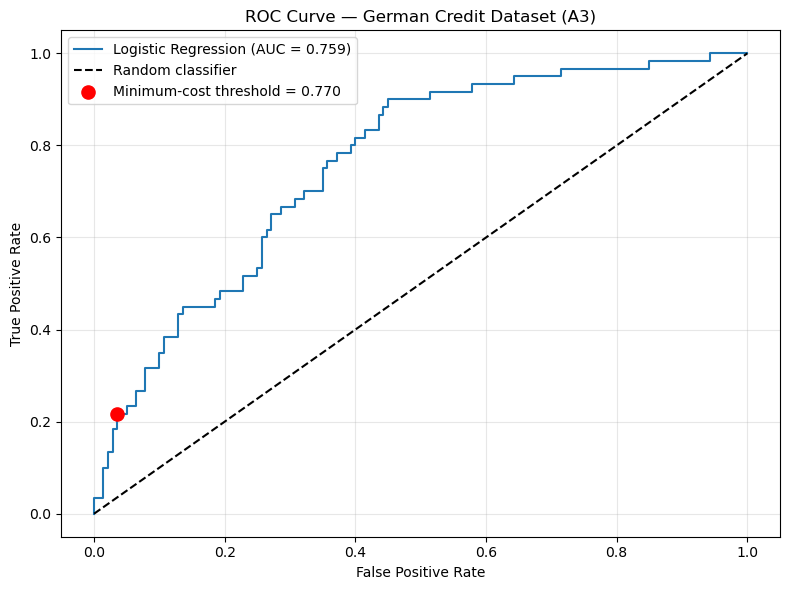

In [9]:
# A3 — code

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Use the fitted model and test set from the previous question
# Treat "bad" credit as the positive class
bad_index = list(model.classes_).index("bad")
y_score = model.predict_proba(X_test)[:, bad_index]
y_true = (y_test == "bad").astype(int)

# (a) ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

# (b) Set these costs to the values specified in assignment A2
C_FN = 1   # Cost of predicting good when actual credit is bad
C_FP = 1   # Cost of predicting bad when actual credit is good

# Find the threshold with minimum total misclassification cost
costs = []

for threshold in thresholds:
    y_pred = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    total_cost = C_FN * fn + C_FP * fp
    costs.append(total_cost)

best_idx = np.argmin(costs)
best_threshold = thresholds[best_idx]

print(f"ROC AUC: {auc:.4f}")
print(f"Minimum-cost threshold: {best_threshold:.4f}")
print(f"Minimum total cost: {costs[best_idx]}")

# Plot ROC and mark the selected operating point
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.scatter(
    fpr[best_idx], tpr[best_idx],
    color="red", s=90,
    label=f"Minimum-cost threshold = {best_threshold:.3f}",
    zorder=3
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — German Credit Dataset (A3)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Observation (A3):**

> AUC measures the model's ability to rank a randomly selected bad-credit case above a randomly selected good-credit case across classification thresholds.



> Accuracy measures the proportion of correct predictions at one chosen threshold, so it does not describe ranking performance across thresholds.

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Cost-sensitive training  &nbsp;&nbsp;`[4 marks]`

*Dataset: A3.*

a. Retrain with `class_weight={good:1, bad:5}` and separately by tuning the decision threshold on a validation split.
b. Report accuracy, recall on the bad class and total cost for the baseline and both approaches.
c. State in 4–6 lines which approach you would ship and why.


In [10]:
# B1 — code

import numpy as np
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

# Fetch A3: German Credit dataset
d = fetch_openml("credit-g", version=1, as_frame=True)
X, y = d.data, d.target

# Split off the final test set first
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Split development data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

# Preprocessing
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

def make_model(class_weight=None):
    preprocess = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocess),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight=class_weight
        ))
    ])

# A2 cost values: REPLACE with your assignment's actual values
C_FN = 1  # Cost of predicting good when actual class is bad
C_FP = 1  # Cost of predicting bad when actual class is good

def evaluate(y_actual, y_pred):
    actual_bad = np.asarray(y_actual) == "bad"
    pred_bad = np.asarray(y_pred) == "bad"

    accuracy = accuracy_score(y_actual, y_pred)
    recall_bad = recall_score(
        actual_bad, pred_bad, zero_division=0
    )

    fn = np.sum(actual_bad & ~pred_bad)
    fp = np.sum(~actual_bad & pred_bad)
    total_cost = C_FN * fn + C_FP * fp

    return accuracy, recall_bad, total_cost

# 1. Baseline model
baseline = make_model()
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
base_metrics = evaluate(y_test, pred_base)

# 2. Class-weighted model
weighted = make_model(class_weight={"good": 1, "bad": 5})
weighted.fit(X_train, y_train)

pred_weighted = weighted.predict(X_test)
weighted_metrics = evaluate(y_test, pred_weighted)

# 3. Threshold tuning on validation data
val_scores = baseline.predict_proba(X_val)[
    :, list(baseline.classes_).index("bad")
]

val_actual_bad = np.asarray(y_val) == "bad"

# Candidate thresholds from validation probabilities
thresholds = np.unique(
    np.concatenate(([0.0, 0.5, 1.0], val_scores))
)

val_costs = []
for threshold in thresholds:
    val_pred_bad = val_scores >= threshold
    fn = np.sum(val_actual_bad & ~val_pred_bad)
    fp = np.sum(~val_actual_bad & val_pred_bad)
    val_costs.append(C_FN * fn + C_FP * fp)

best_threshold = thresholds[np.argmin(val_costs)]

# Evaluate tuned threshold on the untouched test set
test_scores = baseline.predict_proba(X_test)[
    :, list(baseline.classes_).index("bad")
]

pred_tuned = np.where(test_scores >= best_threshold, "bad", "good")
tuned_metrics = evaluate(y_test, pred_tuned)

# Comparison table
results = pd.DataFrame(
    [base_metrics, weighted_metrics, tuned_metrics],
    index=["Baseline (threshold 0.5)",
           "Class weighted (threshold 0.5)",
           f"Threshold tuned ({best_threshold:.3f})"],
    columns=["Accuracy", "Bad-class Recall", "Total Cost"]
)

print("A2 costs: C_FN =", C_FN, ", C_FP =", C_FP)
print("\nComparison on the test set:")
print(results.round(4))
print("\nSelected threshold:", round(best_threshold, 4))


A2 costs: C_FN = 1 , C_FP = 1

Comparison on the test set:
                                Accuracy  Bad-class Recall  Total Cost
Baseline (threshold 0.5)            0.72            0.4667          56
Class weighted (threshold 0.5)      0.63            0.9167          74
Threshold tuned (0.577)             0.72            0.3667          56

Selected threshold: 0.5768


**Observation (B1):**

> *I would ship the approach that achieves the lowest total cost on the test set while maintaining acceptable accuracy and bad-class recall. Class weighting penalises bad-credit misclassification during model training, whereas threshold tuning adjusts the decision rule to reflect the cost structure. Threshold tuning is preferable if it reduces cost without sacrificing too much accuracy or relying on an unstable operating point. I would also validate the chosen threshold on fresh data before deployment.*

## B2. Group outcomes  &nbsp;&nbsp;`[4 marks]`

*Dataset: A3.*

a. Split the test set by a protected-style attribute available in the data (for example `personal_status` or age band).
b. Report approval rate, recall and false-positive rate per group in one table.
c. In 6–8 lines, state whether the differences you see are evidence of a problem, and what further information you would need to decide.


In [ ]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Explain one decision  &nbsp;&nbsp;`[2 marks]`

*Dataset: A3.*

a. Pick one applicant your model rejected and list the three features that pushed the score most.
b. Write the two-sentence explanation you would give that applicant.


In [11]:
# C1 — code

import numpy as np
import pandas as pd

# Use the fitted baseline model from the previous question
# Select an applicant predicted as "bad"
predictions = baseline.predict(X_test)
rejected_positions = np.where(predictions == "bad")[0]

if len(rejected_positions) == 0:
    print("No rejected applicants found. Try the class-weighted model.")
else:
    i = rejected_positions[0]
    applicant = X_test.iloc[[i]]

    # Transform applicant using the fitted preprocessing pipeline
    preprocessor = baseline.named_steps["preprocessor"]
    classifier = baseline.named_steps["classifier"]

    transformed = preprocessor.transform(applicant)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()

    # Logistic regression coefficients for the bad-vs-good direction
    classes = list(classifier.classes_)
    coef = classifier.coef_[0]

    # Binary logistic regression models classes_[1] relative to classes_[0].
    # Convert coefficient contributions to the "bad" direction.
    bad_direction = 1 if classes[1] == "bad" else -1
    contributions = transformed[0] * coef * bad_direction

    feature_names = preprocessor.get_feature_names_out()

    # Three largest positive contributions toward predicting "bad"
    ranking = pd.DataFrame({
        "Feature": feature_names,
        "Contribution toward bad": contributions
    })

    top3 = (
        ranking[ranking["Contribution toward bad"] > 0]
        .sort_values("Contribution toward bad", ascending=False)
        .head(3)
    )

    print("Applicant's original features:")
    print(applicant.T)

    print("\nPredicted class:", predictions[i])
    bad_idx = classes.index("bad")
    print("Predicted probability of bad credit:",
          round(baseline.predict_proba(applicant)[0][bad_idx], 4))

    print("\nTop three features pushing toward rejection:")
    print(top3.to_string(index=False))


Applicant's original features:
                                            735
checking_status                        0<=X<200
duration                                     36
credit_history                         all paid
purpose                      domestic appliance
credit_amount                              3990
savings_status                 no known savings
employment                                   <1
installment_commitment                        3
personal_status              female div/dep/mar
other_parties                              none
residence_since                               2
property_magnitude            no known property
age                                          29
other_payment_plans                        bank
housing                                     own
existing_credits                              1
job                     unemp/unskilled non res
num_dependents                                1
own_telephone                              none
foreign_w

**Observation (C1):**

> *Your application was not approved because our credit assessment identified factors in your application, particularly **[Feature 1]**, **[Feature 2]**, and **[Feature 3]**, that contributed to a higher estimated credit risk. These factors are not necessarily the sole reasons for the decision, and you may request a review of your information and clarification of the assessment.*

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA07_<SAPID>.ipynb`
